# DistilBERT Sentiment Model — Group Psi (CSE 3521)

**Owner:** Kc Luna (ML Engineer, deep model)

This notebook fine-tunes **DistilBERT** to classify Amazon food reviews as **Negative, Neutral, or Positive**, and evaluates it on the **same held-out test set** as our classical models.

**What it does**
1. Reproduces Colin's cleaning and 80/20 train/test split from `Reviews_Feature_Engineering.ipynb` exactly (seed 48), so all models are compared on the same test reviews.
2. Sets aside 10% of the *training* data as a validation set (needed for the M3 training/validation loss curves). The test set is not touched until the final evaluation.
3. Fine-tunes DistilBERT and records training and validation loss.
4. Reports accuracy, precision, recall, F1, a confusion matrix, and training time on the test set.

**Outputs** (saved to `results/` and `models/`)
- `results/loss_curves.png`, `results/confusion_matrix.png`
- `results/distilbert_test_metrics.json`, `results/distilbert_test_predictions.csv`, `results/distilbert_training_log.csv`
- `models/distilbert_sentiment/` — the trained model (~255 MB; do **not** commit to GitHub)

**How to run**
- **Local (AMD GPU):** double-click `start_jupyter.bat`, open this notebook, make sure the kernel is **"Python (CSE 3521 ROCm)"**, and run all cells.
- **Google Colab:** Runtime → Change runtime type → **T4 GPU**, then run all cells. You'll be asked to upload `group_sample_seed48.csv`.

**Tip:** set `QUICK_RUN = True` in the settings cell first. It trains on a small subset in a couple of minutes so you can confirm everything works before the full run.

## 1. Settings

In [17]:
import json
import os
import random
import re
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer

# ---------------- Settings ----------------
# Works whether this notebook sits in the project folder or in the repo's notebooks/ folder
ROOT        = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
DATA_PATH   = os.path.join(ROOT, "data", "group_sample_seed48.csv")   # our team's 50,000-review sample
SEED        = 48                               # Group Psi seed (same as the data split)
MODEL_NAME  = "distilbert-base-uncased"        # plain pre-trained DistilBERT (NOT already fine-tuned for sentiment)
MAX_LENGTH  = 256        # tokens per review; ~94% of our reviews fit without being cut off
BATCH_SIZE  = 32
EPOCHS      = 2
LEARNING_RATE = 3e-5
WARMUP_FRACTION = 0.10   # learning rate ramps up over the first 10% of steps
VAL_FRACTION = 0.10      # 10% of the training set is used for validation
EVAL_EVERY  = 200        # check validation loss every N training steps (points on the loss curve)
USE_CLASS_WEIGHTS = True # give the rare Neutral class more weight in the loss
QUICK_RUN   = False      # True = small subset + 1 epoch, just to test that everything runs

MODEL_DIR   = os.path.join(ROOT, "models", "distilbert_sentiment")
RESULTS_DIR = os.path.join(ROOT, "results")
LABELS = ["Negative", "Neutral", "Positive"]
LABEL2ID = {label: i for i, label in enumerate(LABELS)}
ID2LABEL = {i: label for label, i in LABEL2ID.items()}

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

# Make results repeatable
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [18]:
# Use the GPU if there is one. On AMD (ROCm) and NVIDIA (Colab) GPUs, PyTorch calls it "cuda".
if torch.cuda.is_available():
    device = torch.device("cuda")
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("WARNING: no GPU found - training on CPU will be very slow. Set QUICK_RUN = True to test.")

# Mixed precision (16-bit math) makes training ~2x faster on GPUs with little effect on accuracy
USE_AMP = device.type == "cuda"
print("Mixed precision:", USE_AMP)

Using GPU: AMD Radeon RX 9070 XT
Mixed precision: True


In [19]:
# Google Colab only: upload the dataset if it isn't there yet
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB and not os.path.exists(DATA_PATH):
    from google.colab import files
    os.makedirs(os.path.dirname(DATA_PATH), exist_ok=True)
    print("Please upload group_sample_seed48.csv")
    uploaded = files.upload()
    os.replace(list(uploaded.keys())[0], DATA_PATH)

print("Data file found:", os.path.exists(DATA_PATH))

Data file found: True


## 2. Load and clean the data

This is the **same cleaning as Colin's feature engineering notebook**, so the deep model sees exactly the same reviews as the classical models:
1. Drop the 2 rows with a missing summary.
2. Drop duplicate review text (the same review posted under several product variants).
3. Label 1–2★ Negative, 3★ Neutral, 4–5★ Positive.
4. Remove HTML tags like `<br />` and combine the summary and review into one text.

In [20]:
df = pd.read_csv(DATA_PATH)

clean_df = df.dropna(subset=["Summary"]).copy()
clean_df = clean_df.drop_duplicates(subset=["Text"]).copy()

sentiment_map = {1: "Negative", 2: "Negative", 3: "Neutral", 4: "Positive", 5: "Positive"}
clean_df["Sentiment"] = clean_df["Score"].map(sentiment_map)

def clean_text(text):
    text = re.sub(r"<[^>]+>", " ", text)   # remove HTML tags
    return " ".join(text.split())           # remove extra spaces and line breaks

clean_df["CleanSummary"] = clean_df["Summary"].apply(clean_text)
clean_df["CleanText"] = clean_df["Text"].apply(clean_text)
clean_df["CombinedText"] = clean_df["CleanSummary"] + " " + clean_df["CleanText"]

print("Rows after cleaning:", len(clean_df))   # expected: 46,261
print(clean_df["Sentiment"].value_counts())

Rows after cleaning: 46261
Sentiment
Positive    36065
Negative     6653
Neutral      3543
Name: count, dtype: int64


## 3. Train / validation / test split

- **Test (20%)** — identical to Colin's split (same seed, same stratification). Used **once**, at the very end.
- **Validation (10% of training)** — used during training to draw the validation loss curve and pick the best checkpoint.
- **Train** — what the model learns from.

In [21]:
# Same call as Colin's notebook -> same test set as the classical models
train_df, test_df = train_test_split(
    clean_df, test_size=0.20, random_state=SEED, stratify=clean_df["Sentiment"]
)

# Carve a validation set out of the training data only
train_df, val_df = train_test_split(
    train_df, test_size=VAL_FRACTION, random_state=SEED, stratify=train_df["Sentiment"]
)

if QUICK_RUN:
    train_df = train_df.sample(n=2000, random_state=SEED)
    val_df = val_df.sample(n=500, random_state=SEED)
    EPOCHS = 1
    EVAL_EVERY = 20
    print(">>> QUICK_RUN is on: using a small subset and 1 epoch <<<")

print(f"Train: {len(train_df):,}   Validation: {len(val_df):,}   Test: {len(test_df):,}")

summary = pd.DataFrame({
    name: part["Sentiment"].value_counts(normalize=True).reindex(LABELS).round(4)
    for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]
})
display(summary)

majority = test_df["Sentiment"].value_counts(normalize=True).max()
print(f"Majority-class baseline on the test set (always 'Positive'): accuracy = {majority:.4f}")

Train: 33,307   Validation: 3,701   Test: 9,253


,train,validation,test
Sentiment,,,
Negative,0.1438,0.1437,0.1438
Neutral,0.0766,0.0767,0.0766
Positive,0.7796,0.7795,0.7795


Majority-class baseline on the test set (always 'Positive'): accuracy = 0.7795


## 4. Tokenizer

DistilBERT doesn't read words directly. The **tokenizer** splits text into word pieces (e.g. "unbelievably" → `un`, `##believ`, `##ably`) and turns them into ID numbers. It also adds a special `[CLS]` token at the start, whose final representation is used to classify the whole review.

In [22]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train_df["CombinedText"].iloc[0]
print("Example review:", example[:120], "...")
print("Tokens:", tokenizer.tokenize(example)[:20], "...")

# How many reviews are longer than MAX_LENGTH tokens (and will be cut off)?
# (A warning about "longer than the specified maximum sequence length" here is expected and harmless:
#  this check measures full lengths on purpose. Training always cuts reviews at MAX_LENGTH.)
lengths = [len(ids) for ids in tokenizer(train_df["CombinedText"].tolist()[:5000])["input_ids"]]
print(f"Median length: {np.median(lengths):.0f} tokens | "
      f"cut off at {MAX_LENGTH}: {np.mean(np.array(lengths) > MAX_LENGTH):.1%} of reviews")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (842 > 512). Running this sequence through the model will result in indexing errors


Example review: Great Product I received in a timely manner. The product was great! Very fresh. Will buy from again. ...
Tokens: ['great', 'product', 'i', 'received', 'in', 'a', 'timely', 'manner', '.', 'the', 'product', 'was', 'great', '!', 'very', 'fresh', '.', 'will', 'buy', 'from'] ...
Median length: 78 tokens | cut off at 256: 5.7% of reviews


In [23]:
def make_loader(frame, shuffle):
    texts = frame["CombinedText"].tolist()
    labels = frame["Sentiment"].map(LABEL2ID).tolist()
    data = list(zip(texts, labels))

    def collate(batch):
        batch_texts, batch_labels = zip(*batch)
        # Pad each batch only to its longest review (faster than always padding to 256)
        enc = tokenizer(list(batch_texts), truncation=True, max_length=MAX_LENGTH,
                        padding=True, return_tensors="pt")
        enc["labels"] = torch.tensor(batch_labels)
        return enc

    generator = torch.Generator().manual_seed(SEED)
    return DataLoader(data, batch_size=BATCH_SIZE, shuffle=shuffle,
                      collate_fn=collate, generator=generator, num_workers=0)

train_loader = make_loader(train_df, shuffle=True)
val_loader = make_loader(val_df, shuffle=False)
test_loader = make_loader(test_df, shuffle=False)
print("Training batches per epoch:", len(train_loader))

Training batches per epoch: 1041


## 5. Model, loss, and optimizer

- **Model:** pre-trained DistilBERT with a new 3-class classification layer on top. The pre-trained part already understands English; fine-tuning teaches it our task.
- **Loss:** cross-entropy. With `USE_CLASS_WEIGHTS = True`, mistakes on the rare **Neutral** class (7.7% of reviews) cost more, so the model doesn't just ignore it.
- **Optimizer:** AdamW with a learning rate that warms up, then decreases linearly — the standard recipe for fine-tuning BERT-style models.

In [24]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
).to(device)
# The load report above listing UNEXPECTED / MISSING weights is normal: the pre-training layers
# are dropped and a new, untrained 3-class classifier layer is added - that's the part we fine-tune.
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} million")

if USE_CLASS_WEIGHTS:
    weights = compute_class_weight("balanced", classes=np.arange(len(LABELS)),
                                   y=train_df["Sentiment"].map(LABEL2ID).values)
    print("Class weights:", dict(zip(LABELS, np.round(weights, 2))))
    class_weights = torch.tensor(weights, dtype=torch.float, device=device)
else:
    class_weights = None
loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

total_steps = len(train_loader) * EPOCHS
warmup_steps = int(WARMUP_FRACTION * total_steps)

def lr_lambda(step):
    if step < warmup_steps:
        return step / max(1, warmup_steps)
    return max(0.0, (total_steps - step) / max(1, total_steps - warmup_steps))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
print("Total training steps:", total_steps)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 67.0 million
Class weights: {'Negative': np.float64(2.32), 'Neutral': np.float64(4.35), 'Positive': np.float64(0.43)}
Total training steps: 2082


## 6. Training

In [25]:
@torch.no_grad()
def evaluate(loader):
    # Returns average loss, true labels, predicted labels, and class probabilities
    model.eval()
    total_loss, n = 0.0, 0
    all_true, all_pred, all_prob = [], [], []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), labels)
        total_loss += loss.item() * len(labels)
        n += len(labels)
        probs = torch.softmax(logits.float(), dim=-1)
        all_true.extend(labels.cpu().tolist())
        all_pred.extend(probs.argmax(dim=-1).cpu().tolist())
        all_prob.extend(probs.cpu().tolist())
    model.train()
    return total_loss / n, np.array(all_true), np.array(all_pred), np.array(all_prob)

In [26]:
log = []                    # one row per validation check, for the loss curves
best_val_f1, best_state = -1.0, None
running_loss, running_n = 0.0, 0
step = 0

model.train()
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        labels = batch.pop("labels")

        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        loss = loss_fn(logits.float(), labels)

        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # keeps updates stable
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        running_loss += loss.item() * len(labels)
        running_n += len(labels)
        step += 1

        if step % EVAL_EVERY == 0 or step == total_steps:
            val_loss, y_true, y_pred, _ = evaluate(val_loader)
            val_f1 = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)[2]
            train_loss = running_loss / running_n
            running_loss, running_n = 0.0, 0
            elapsed = time.time() - start_time
            log.append({"step": step, "epoch": round(step / len(train_loader), 2),
                        "train_loss": train_loss, "val_loss": val_loss,
                        "val_macro_f1": val_f1, "minutes": elapsed / 60})
            print(f"step {step:>5}/{total_steps} | epoch {step / len(train_loader):.2f} | "
                  f"train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
                  f"val macro-F1 {val_f1:.4f} | {elapsed / 60:.1f} min")

            # Keep the version of the model that does best on validation
            if val_f1 > best_val_f1:
                best_val_f1 = val_f1
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

training_minutes = (time.time() - start_time) / 60
print(f"\nTraining time: {training_minutes:.1f} minutes | best validation macro-F1: {best_val_f1:.4f}")

log_df = pd.DataFrame(log)
log_df.to_csv(os.path.join(RESULTS_DIR, "distilbert_training_log.csv"), index=False)

step   200/2082 | epoch 0.19 | train loss 0.9075 | val loss 0.6190 | val macro-F1 0.7121 | 0.3 min
step   400/2082 | epoch 0.38 | train loss 0.5951 | val loss 0.5680 | val macro-F1 0.7221 | 0.7 min
step   600/2082 | epoch 0.58 | train loss 0.5560 | val loss 0.5582 | val macro-F1 0.7289 | 1.0 min
step   800/2082 | epoch 0.77 | train loss 0.5577 | val loss 0.4886 | val macro-F1 0.7217 | 1.4 min
step  1000/2082 | epoch 0.96 | train loss 0.5436 | val loss 0.4841 | val macro-F1 0.7368 | 1.7 min
step  1200/2082 | epoch 1.15 | train loss 0.4136 | val loss 0.5254 | val macro-F1 0.7422 | 2.1 min
step  1400/2082 | epoch 1.34 | train loss 0.3778 | val loss 0.5462 | val macro-F1 0.7529 | 2.4 min
step  1600/2082 | epoch 1.54 | train loss 0.4019 | val loss 0.5344 | val macro-F1 0.7478 | 2.8 min
step  1800/2082 | epoch 1.73 | train loss 0.4110 | val loss 0.5109 | val macro-F1 0.7591 | 3.1 min
step  2000/2082 | epoch 1.92 | train loss 0.3890 | val loss 0.5096 | val macro-F1 0.7510 | 3.4 min
step  2082

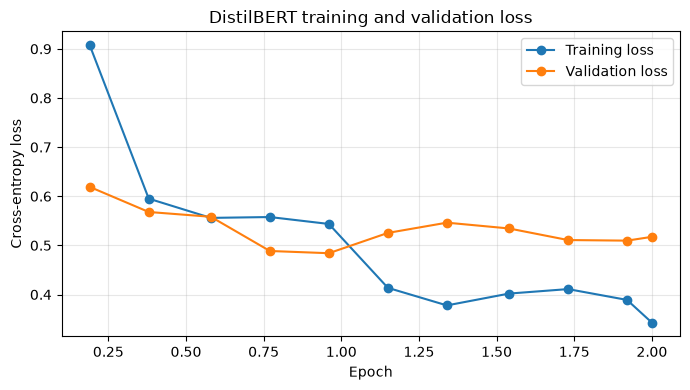

In [27]:
# Training and validation loss curves (required for Milestone 3)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(log_df["epoch"], log_df["train_loss"], marker="o", label="Training loss")
ax.plot(log_df["epoch"], log_df["val_loss"], marker="o", label="Validation loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("DistilBERT training and validation loss")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "loss_curves.png"), dpi=200)
plt.show()

# How to read it: both lines going down = learning. If validation loss starts rising
# while training loss keeps falling, the model is overfitting (memorizing the training set).

## 7. Final evaluation on the test set

The test set is used here **for the first and only time**, with the best checkpoint from validation. These are the numbers that go in the M3 model comparison table.

In [28]:
model.load_state_dict(best_state)
model.to(device)

test_loss, y_true, y_pred, y_prob = evaluate(test_loader)

accuracy = accuracy_score(y_true, y_pred)
precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
w_precision, w_recall, w_f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted", zero_division=0)

print(f"Test accuracy      : {accuracy:.4f}   (majority baseline {majority:.4f})")
print(f"Macro precision    : {precision:.4f}")
print(f"Macro recall       : {recall:.4f}")
print(f"Macro F1           : {f1:.4f}")
print(f"Training time      : {training_minutes:.1f} minutes")
print()
print(classification_report(y_true, y_pred, target_names=LABELS, digits=4, zero_division=0))

Test accuracy      : 0.8835   (majority baseline 0.7795)
Macro precision    : 0.7299
Macro recall       : 0.7864
Macro F1           : 0.7482
Training time      : 3.6 minutes

              precision    recall  f1-score   support

    Negative     0.8080    0.7844    0.7960      1331
     Neutral     0.4033    0.6502    0.4978       709
    Positive     0.9783    0.9247    0.9508      7213

    accuracy                         0.8835      9253
   macro avg     0.7299    0.7864    0.7482      9253
weighted avg     0.9097    0.8835    0.8938      9253



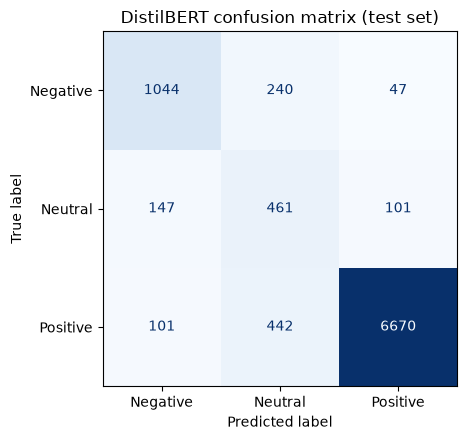

In [29]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title("DistilBERT confusion matrix (test set)")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=200)
plt.show()

In [30]:
# Save metrics and every test prediction (for the comparison table and error analysis)
per_class = precision_recall_fscore_support(y_true, y_pred, zero_division=0)
metrics = {
    "model": MODEL_NAME, "test_size": int(len(y_true)),
    "accuracy": accuracy, "macro_precision": precision, "macro_recall": recall, "macro_f1": f1,
    "weighted_precision": w_precision, "weighted_recall": w_recall, "weighted_f1": w_f1,
    "majority_baseline_accuracy": float(majority),
    "training_minutes": training_minutes, "device": str(torch.cuda.get_device_name(0) if USE_AMP else "cpu"),
    "per_class": {LABELS[i]: {"precision": per_class[0][i], "recall": per_class[1][i],
                              "f1": per_class[2][i], "support": int(per_class[3][i])}
                  for i in range(len(LABELS))},
    "settings": {"max_length": MAX_LENGTH, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
                 "learning_rate": LEARNING_RATE, "class_weights": USE_CLASS_WEIGHTS,
                 "seed": SEED, "quick_run": QUICK_RUN},
}
with open(os.path.join(RESULTS_DIR, "distilbert_test_metrics.json"), "w") as f:
    json.dump(metrics, f, indent=2, default=float)

pred_df = test_df[["Id", "Score", "Sentiment", "CombinedText"]].copy()
pred_df["Predicted"] = [ID2LABEL[i] for i in y_pred]
for i, label in enumerate(LABELS):
    pred_df[f"prob_{label}"] = y_prob[:, i].round(4)
pred_df["Correct"] = pred_df["Sentiment"] == pred_df["Predicted"]
pred_df.to_csv(os.path.join(RESULTS_DIR, "distilbert_test_predictions.csv"), index=False)
print("Saved metrics and predictions to", RESULTS_DIR)

# A few mistakes to start the error analysis
pd.set_option("display.max_colwidth", 200)
display(pred_df.loc[~pred_df["Correct"], ["Sentiment", "Predicted", "CombinedText"]].head(10))

Saved metrics and predictions to .\results


,Sentiment,Predicted,CombinedText
12634,Positive,Neutral,"only 25% fruit juice Tasty Grape Drink, but it is basiclly an organic Kool Aid! Had a good grape flavor, not too sweet, but not 100% juice."
5240,Positive,Neutral,"Not your ordinary candy review. Not your ordinary candy, either. This is going to seem like an unusual selling point for a candy, but I have a prescription which gives me nausea, and Ginger Altoid..."
8922,Positive,Neutral,"European style orange This is not like Orange Crush. It is less sweet and more refreshing, like the European orangades or Orangina, and I adore it!"
35216,Positive,Negative,Deceptive Description I assumed that the description of 9 pound box of assorted coffee beans referred to the weight of the coffee. It does not. Sure enough careful reading revealed that the weight...
47662,Negative,Neutral,OK My son had a constipation problem when he was around 13 months. He tried this at a family member's house and loved it. It also helped with the constipation. So I ordered a pack and he really di...
6891,Positive,Neutral,"Arrived as ordered I did not have any problems receiving an inferior product. I applaud this company's use of BPA-free cans, but the use of guar gum seems unecessary. Whenever I open a can it has ..."
45920,Positive,Neutral,"Honestly, Q tonic water is better Fever Tree is a good product. It has a little spicier flavor than Q tonic water. My personal preference(and these things are very subjective)is Q."
45677,Positive,Neutral,"Not quite as expected Purchased a Bonsai that arrived a couple of days later than described however, shipping delays are understandable and not always the fault of the shipper. The product did not..."
9714,Positive,Neutral,"Good This is good dog food, but I stopped buying it, because one of my dogs (I have two) did not like it. She is not a big fan of can food in general."
12606,Negative,Neutral,"Not what I expected I ordered these on a whim since I discovered awhile ago with friends that I love mochi/daifuku. First of all, I was really confused by them. I thought I'd be getting a package ..."


In [31]:
# Save the trained model + tokenizer so the Streamlit app can load it (~255 MB, do NOT commit to GitHub)
if not QUICK_RUN:
    model.save_pretrained(MODEL_DIR)
    tokenizer.save_pretrained(MODEL_DIR)
    print("Model saved to", MODEL_DIR)
else:
    print("QUICK_RUN is on, so the model was not saved. Set QUICK_RUN = False for the real run.")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to .\models\distilbert_sentiment


## 8. Using the saved model (for the app)

```python
from transformers import AutoTokenizer, AutoModelForSequenceClassification
tokenizer = AutoTokenizer.from_pretrained("models/distilbert_sentiment")
model = AutoModelForSequenceClassification.from_pretrained("models/distilbert_sentiment")
```

In [32]:
def predict(review):
    model.eval()
    enc = tokenizer(clean_text(review), truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
    with torch.no_grad():
        probs = torch.softmax(model(**enc).logits.float(), dim=-1)[0].cpu().numpy()
    return {label: round(float(p), 3) for label, p in zip(LABELS, probs)}

for review in ["These chips are not good at all.",
               "Great price, fast shipping, and my kids love them!",
               "It's okay. Nothing special, but not bad either."]:
    print(predict(review), "<-", review)

{'Negative': 0.987, 'Neutral': 0.011, 'Positive': 0.002} <- These chips are not good at all.
{'Negative': 0.002, 'Neutral': 0.007, 'Positive': 0.991} <- Great price, fast shipping, and my kids love them!
{'Negative': 0.039, 'Neutral': 0.942, 'Positive': 0.02} <- It's okay. Nothing special, but not bad either.
